# DSP Lab 3: Work with YourTTS

# Preparation for Work

In [16]:
# Hide all warnings for the session
import warnings
warnings.filterwarnings("ignore")

- ### For this task, Python 3.10 is recommended.

In [17]:
import sys
print(sys.version)

3.10.22 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:15:38) [MSC v.1942 64 bit (AMD64)]


**Note**. TTS is tested on Ubuntu 18.04 with python >= 3.9, < 3.12. If version is newer (3.12+). Run this in your terminal: `conda install python=3.10 -y`

- ### Install TTS library: `pip install TTS`

More about TTS library, see: "https://pypi.org/project/TTS/", "https://github.com/coqui-ai/tts", "https://coqui-tts.readthedocs.io/en/latest/inference.html"

In [18]:
import TTS
print(TTS.__version__)

0.22.0


- ### Load the pretrained YourTTS model:

In [19]:
import torch
from TTS.api import TTS

# Get device
device = "cuda" if torch.cuda.is_available() else "cpu"

# List available TTS models
models = TTS().list_models().list_models()

for m in models:
    if "multilingual" in m or "your_tts" in m:
        print(m)

tts_models/multilingual/multi-dataset/xtts_v2
tts_models/multilingual/multi-dataset/xtts_v1.1
tts_models/multilingual/multi-dataset/your_tts
tts_models/multilingual/multi-dataset/bark
voice_conversion_models/multilingual/vctk/freevc24


In [20]:
# Initialize TTS with the target model name
tts = TTS(
model_name="tts_models/multilingual/multi-dataset/your_tts"
).to(device)

 > tts_models/multilingual/multi-dataset/your_tts is already downloaded.
 > Using model: vits
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:80
 | > log_func:np.log10
 | > min_level_db:0
 | > frame_shift_ms:None
 | > frame_length_ms:None
 | > ref_level_db:None
 | > fft_size:1024
 | > power:None
 | > preemphasis:0.0
 | > griffin_lim_iters:None
 | > signal_norm:None
 | > symmetric_norm:None
 | > mel_fmin:0
 | > mel_fmax:None
 | > pitch_fmin:None
 | > pitch_fmax:None
 | > spec_gain:20.0
 | > stft_pad_mode:reflect
 | > max_norm:1.0
 | > clip_norm:True
 | > do_trim_silence:False
 | > trim_db:60
 | > do_sound_norm:False
 | > do_amp_to_db_linear:True
 | > do_amp_to_db_mel:True
 | > do_rms_norm:False
 | > db_level:None
 | > stats_path:None
 | > base:10
 | > hop_length:256
 | > win_length:1024
 > Model fully restored. 
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:64
 | > log_func:np.log10
 | > min_level_db:-

### Information about the model

In [161]:
print(tts.model_name)          # tts_models/multilingual/multi-dataset/your_tts
print(tts.is_multi_speaker)    # True
print(tts.is_multi_lingual)    # True
print(tts.languages)           # ['en', 'fr-fr', 'pt-br']
print(len(tts.speakers))       # number of built-in voices
print(tts.speakers)            # List speakers

tts_models/multilingual/multi-dataset/your_tts
True
True
['en', 'fr-fr', 'pt-br']
6
['female-en-5', 'female-en-5\n', 'female-pt-4\n', 'male-en-2', 'male-en-2\n', 'male-pt-3\n']


- ### Check the languages supported by the pretrained model:

In [162]:
print(tts.languages)

['en', 'fr-fr', 'pt-br']


**In the report.** 

✓ List the supported languages and report whether Lithuanian is available among the supported languages;

**[Answer].** Supported languages: English (en), French (fr-fr) and Brazilian Portuguese (pt-br). Lithuanian (lt) is not among the supported languages.

### Description

In [163]:
import json, os
import TTS

path = os.path.join(os.path.dirname(TTS.__file__), ".models.json")
with open(path, encoding="utf-8") as f:
    models = json.load(f)

print(json.dumps(models["tts_models"]["multilingual"]["multi-dataset"]["your_tts"], indent=2))

# !tts --model_info_by_name "tts_models/multilingual/multi-dataset/your_tts"

{
  "description": "Your TTS model accompanying the paper https://arxiv.org/abs/2112.02418",
  "github_rls_url": "https://coqui.gateway.scarf.sh/v0.10.1_models/tts_models--multilingual--multi-dataset--your_tts.zip",
  "default_vocoder": null,
  "commit": "e9a1953e",
  "license": "CC BY-NC-ND 4.0",
  "contact": "egolge@coqui.ai"
}


# 1. Zero-Shot Speech Synthesis (English)

### Record and load a speech signal

Record yourself saying the following sentence: “This is a test of the speech synthesis system.”

Save the recording as “reference_en.wav”. This recording will serve as both a natural speech
reference and a reference for the target speaker's voice.

In [205]:
import matplotlib.pyplot as plt
import numpy as np
import librosa
from IPython.display import Audio

#### Load the file

In [206]:
filename = 'reference_en.wav'
y, sr = librosa.load(filename, sr=None, mono=True) # load the audio file with its original sampling rate
# sr=None uses the native sampling rate
# mono=True convert signal to mono

#### Listen to playback

In [207]:
Audio(data=y, rate=sr) # listen to playback

### Information about the reference recording (duration, sampling frequency, and audio format);

In [208]:
import soundfile as sf
import os

path = "reference_en.wav"
info = sf.info(path)

print("File size:       ", os.path.getsize(path), "bytes") # 373 KB on disk - storage size
print("Duration:        ", round(info.duration, 3), "seconds")
print("Sampling rate:   ", info.samplerate, "Hz") # 48 kHz - standard for phones, laptops and video.
print("Channels:        ", info.channels)     # 1 - Mono, a single audio track
print("Format:          ", info.format)       # WAV (Microsoft) [WAV]
print("Subtype (bit depth):", info.subtype)   # Signed 16 bit PCM [PCM_16]

File size:        382244 bytes
Duration:         3.981 seconds
Sampling rate:    48000 Hz
Channels:         1
Format:           WAV
Subtype (bit depth): PCM_16


In [209]:
print(f"Sampling frequency / rate (sr): {sr} Hz")

Sampling frequency / rate (sr): 48000 Hz


In [210]:
print(f"Number of samples (signal length): {y.shape[0]} samples")
print("number of samples: ", y.shape)

Number of samples (signal length): 191100 samples
number of samples:  (191100,)


In [211]:
print("Signal duration (s): ", y.shape[0] / sr)

# or 
print("Signal duration (s): ", librosa.get_duration(y=y, sr=sr))

Signal duration (s):  3.98125
Signal duration (s):  3.98125


### Plotting the natural signal

#### Waveform

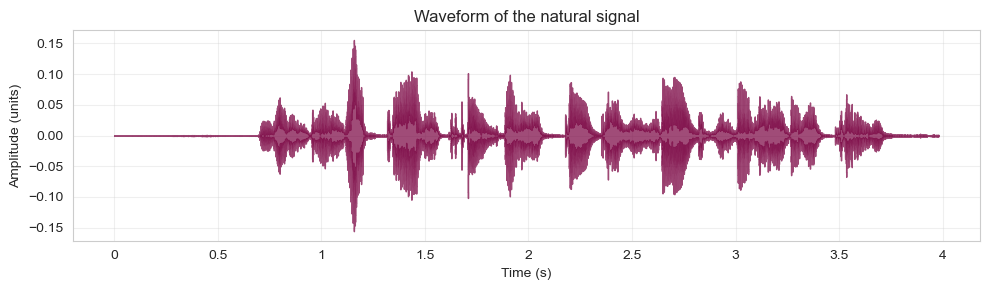

In [212]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(10, 3))

librosa.display.waveshow(y, sr=sr, ax=ax, color="#78003F", alpha=0.7)
ax.set_title("Waveform of the natural signal")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude (units)")
ax.set_axisbelow(True)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Magnitude spectra

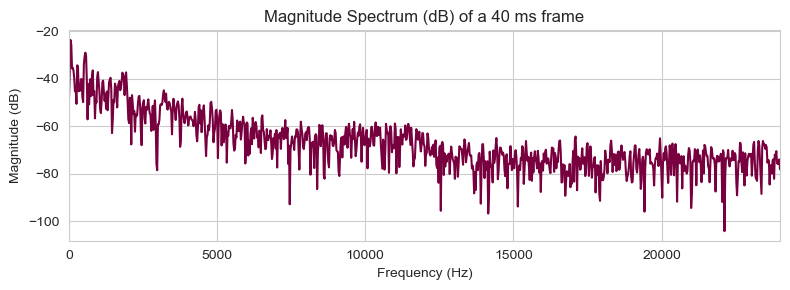

In [214]:
# 1. Pick a 40 ms frame
frame_ms = 40
N = int(sr * frame_ms / 1000)          # 1920 samples at 48000 Hz
start_time = 0.5                       # seconds, choose a voiced part (a vowel)
start = int(start_time * sr)
frame = y[start:start + N]
assert len(frame) == N, "start_time too close to end of file"

# 2. Window
windowed = frame * np.hanning(N)       # reduces spectral leakage

# 3. FFT -> magnitude -> dB
X = np.fft.rfft(windowed)
mag = np.abs(X)
mag_db = 20 * np.log10(mag + 1e-10)    # small value avoids log(0)
freqs = np.fft.rfftfreq(N, d=1/sr)     # frequency of each FFT bin

plt.figure(figsize=(8, 3))
plt.plot(freqs, mag_db, color="#78003F")
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')
plt.title('Magnitude Spectrum (dB) of a 40 ms frame')
plt.xlim(0, sr / 2)
plt.grid(True)
plt.tight_layout()
plt.show()

#### Fundamental frequency (F0) contours

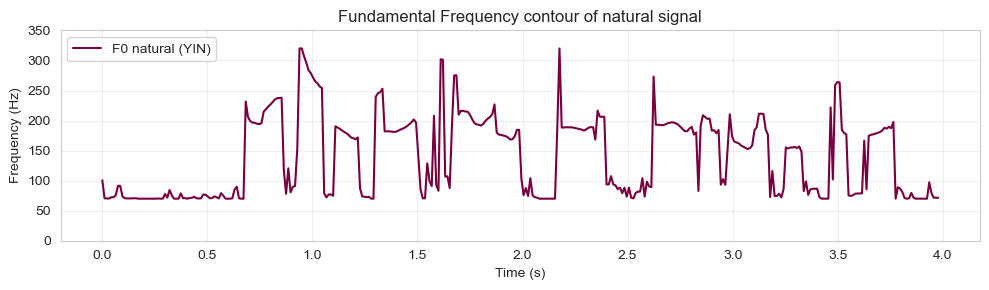

In [215]:
# Extract fundamental frequency using YIN
f0 = librosa.yin(y, fmin=70, fmax=320, sr=sr) #Typical ranges for speech adult female: fmin=70, fmax=300
times = librosa.times_like(f0, sr=sr)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(times, f0,  color="#78003F", label='F0 natural (YIN)')

ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_title('Fundamental Frequency contour of natural signal')

ax.set_ylim(0, 350)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

### Speech synthesis

Using the pretrained YourTTS model, synthesize the same sentence:

In [216]:
tts.tts_to_file(
text="This is a test of the speech synthesis system.",
speaker_wav="reference_en.wav",
language="en",
file_path="output.wav"
)

 > Text splitted to sentences.
['This is a test of the speech synthesis system.']
 > Processing time: 9.563085556030273
 > Real-time factor: 2.2296772105456455


'output.wav'

#### Load the file

In [224]:
y_syn, sr_syn = librosa.load("output.wav", sr=None)

#### Listen to playback

In [218]:
Audio(data=y_syn, rate=sr_syn) # listen to playback

### Information about the synthesized recording (duration, sampling frequency, and audio format);

In [219]:
import soundfile as sf
import os

path = "output.wav"
info = sf.info(path)

print("File size:       ", os.path.getsize(path), "bytes")
print("Duration:        ", round(info.duration, 3), "seconds")
print("Sampling rate:   ", info.samplerate, "Hz") # 16 kHz
print("Channels:        ", info.channels)     # 1 - Mono, a single audio track
print("Format:          ", info.format)       # WAV (Microsoft) [WAV]
print("Subtype (bit depth):", info.subtype)   # Signed 16 bit PCM [PCM_16]

File size:        137292 bytes
Duration:         4.289 seconds
Sampling rate:    16000 Hz
Channels:         1
Format:           WAV
Subtype (bit depth): PCM_16


### Plotting the synthesized signal

#### Waveform

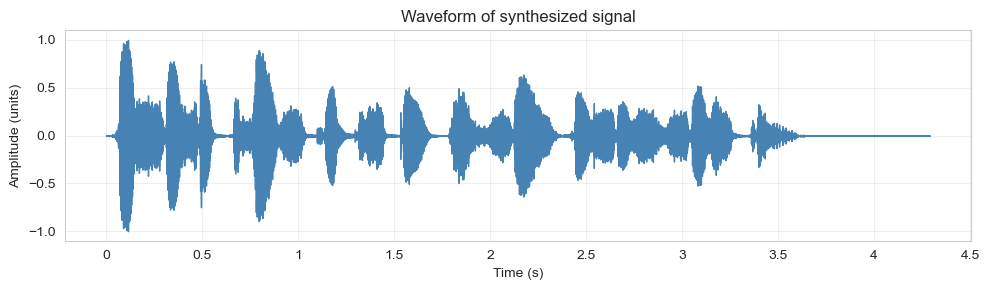

In [220]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(10, 3))

librosa.display.waveshow(y_syn, sr=sr_syn, ax=ax, color='steelblue')
ax.set_title("Waveform of synthesized signal")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude (units)")
ax.set_axisbelow(True)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Magnitude spectra

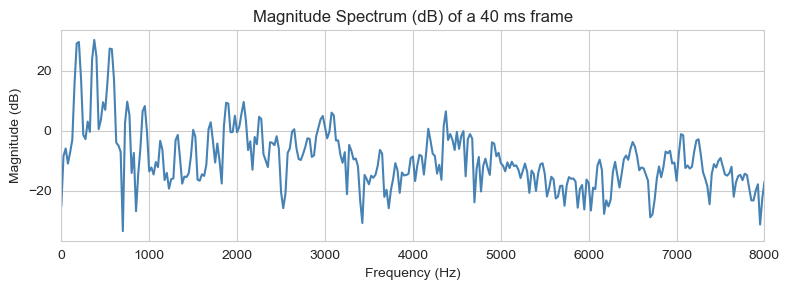

In [227]:
# 1. Pick a 40 ms frame
frame_ms = 40
N = int(sr_syn * frame_ms / 1000)          # 1920 samples at 48000 Hz
start_time = 0.5                       # seconds, choose a voiced part (a vowel)
start = int(start_time * sr_syn)
frame = y_syn[start:start + N]
assert len(frame) == N, "start_time too close to end of file"

# 2. Window
windowed = frame * np.hanning(N)       # reduces spectral leakage

# 3. FFT -> magnitude -> dB
X = np.fft.rfft(windowed)
mag = np.abs(X)
mag_db = 20 * np.log10(mag + 1e-10)    # small value avoids log(0)
freqs = np.fft.rfftfreq(N, d=1/sr_syn)     # frequency of each FFT bin

plt.figure(figsize=(8, 3))
plt.plot(freqs, mag_db, color="steelblue")
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')
plt.title('Magnitude Spectrum (dB) of a 40 ms frame')
plt.xlim(0, sr_syn / 2)
plt.grid(True)
plt.tight_layout()
plt.show()

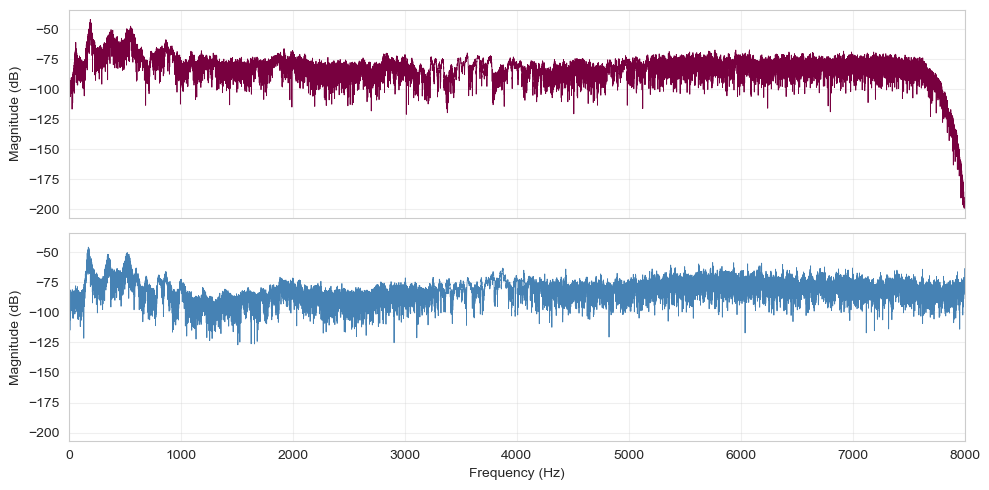

In [228]:
import numpy as np
import librosa
import matplotlib.pyplot as plt

y, sr = librosa.load("reference_en.wav", sr=None, mono=True)         # 48000
y_syn, sr_syn = librosa.load("output.wav", sr=None, mono=True)       # 16000

# resample natural to the synthesized rate, keep the originals untouched
y16 = librosa.resample(y, orig_sr=sr, target_sr=sr_syn)

# peak normalization
y16_n = y16 / np.max(np.abs(y16))
y_syn_n = y_syn / np.max(np.abs(y_syn))

def magnitude_spectrum_db(y, sr):
    N = len(y)
    X = np.fft.rfft(y * np.hanning(N))
    mag_db = 20 * np.log10(np.abs(X) / N + 1e-10)
    freqs = np.fft.rfftfreq(N, d=1 / sr)
    return freqs, mag_db

freqs_nat, db_nat = magnitude_spectrum_db(y16_n, sr_syn)
freqs_syn, db_syn = magnitude_spectrum_db(y_syn_n, sr_syn)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, sharey=True)

axes[0].plot(freqs_nat, db_nat, color="#78003F", linewidth=0.6)

axes[1].plot(freqs_syn, db_syn, color="steelblue", linewidth=0.6)
axes[1].set_xlabel("Frequency (Hz)")

for ax in axes:
    ax.set_ylabel("Magnitude (dB)")
    ax.set_xlim(0, 8000)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig("images/magnitude_en.pdf", dpi=300, bbox_inches="tight")
plt.show()

#### Fundamental frequency (F0) contours

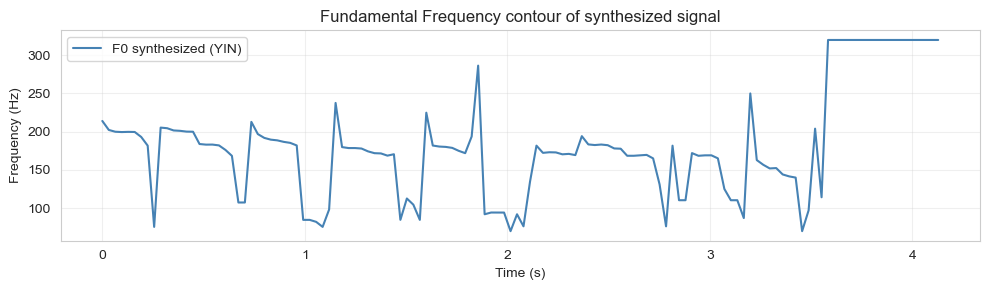

In [182]:
# Extract fundamental frequency using YIN
f0 = librosa.yin(y_syn, fmin=70, fmax=320, sr=sr_syn)
times = librosa.times_like(f0, sr=sr_syn)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(times, f0, color="steelblue", label='F0 synthesized (YIN)')

ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_title('Fundamental Frequency contour of synthesized signal')

ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

### Comparison

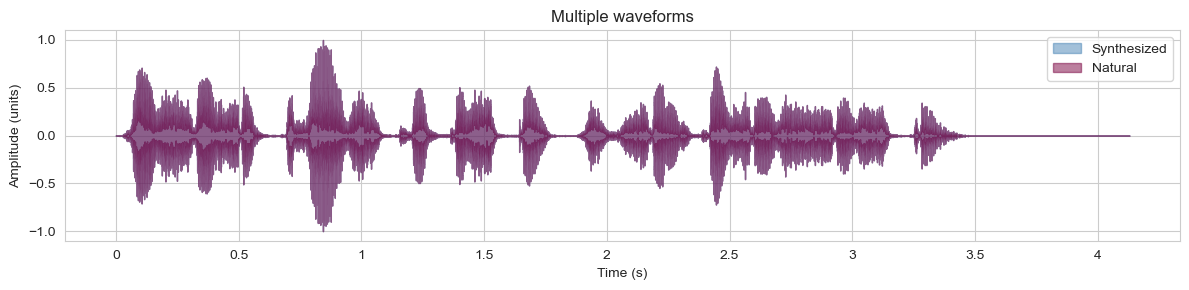

In [183]:
fig, ax = plt.subplots(figsize=(12, 3))

librosa.display.waveshow(y_syn, sr=sr_syn, color="steelblue", alpha=0.5, ax=ax, label="Synthesized")
librosa.display.waveshow(y, sr=sr, color="#78003F", alpha=0.5, ax=ax, label="Natural")

ax.set_title("Multiple waveforms")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude (units)")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

onset natural 0.00 s, synthesized 0.00 s, shift = 0.00 s


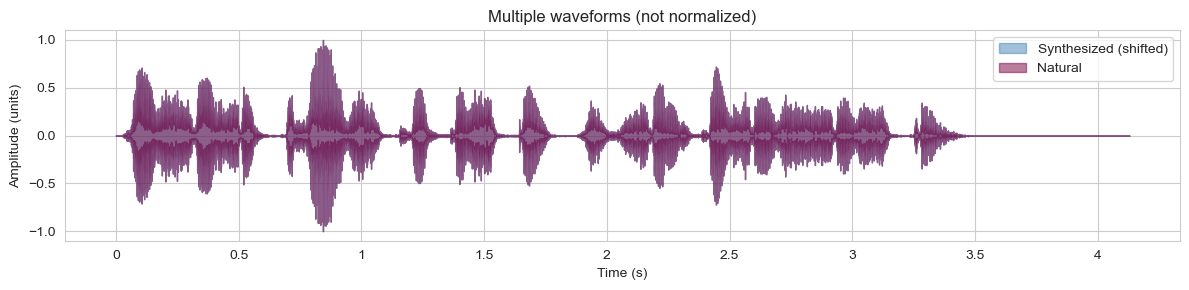

In [184]:
# where speech starts in each signal (sample index)
y_trimmed_nat, (s_nat, e_nat) = librosa.effects.trim(y, top_db=30)
y_trimmed_syn, (s_syn, e_syn) = librosa.effects.trim(y_syn, top_db=30)

# convert to seconds
onset_nat = s_nat / sr
onset_syn = s_syn / sr_syn
shift = onset_nat - onset_syn 
print(f"onset natural {onset_nat:.2f} s, synthesized {onset_syn:.2f} s, shift = {shift:.2f} s")

fig, ax = plt.subplots(figsize=(12, 3))

librosa.display.waveshow(y_syn, sr=sr_syn, color="steelblue", alpha=0.5, ax=ax,
                         label="Synthesized (shifted)", offset=shift)
librosa.display.waveshow(y, sr=sr, color="#78003F", alpha=0.5, ax=ax,
                         label="Natural")

ax.set(title="Multiple waveforms (not normalized)",
       xlabel="Time (s)", ylabel="Amplitude (units)")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

onset natural 0.67 s, synthesized 0.00 s, shift = 0.67 s


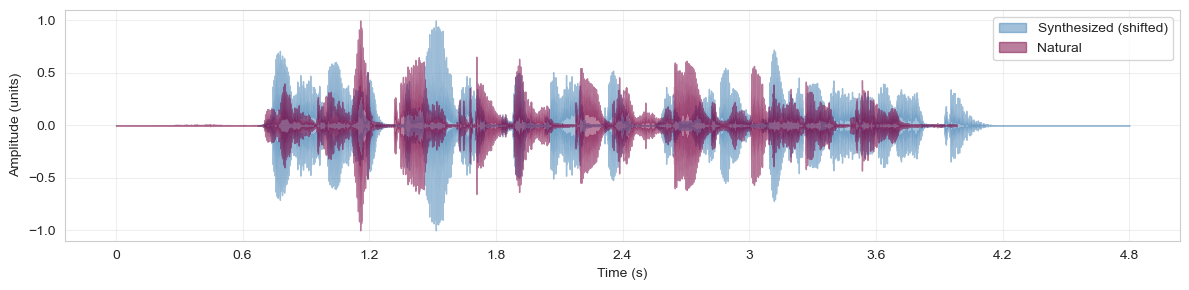

In [185]:
sr_norm = 16000
y_nat, _ = librosa.load("reference_en.wav", sr=sr_norm, mono=True)
y_syn, _ = librosa.load("output.wav", sr=sr_norm, mono=True)

# where speech starts in each signal (sample index)
_, (s_nat, e_nat) = librosa.effects.trim(y_nat, top_db=30)
_, (s_syn, e_syn) = librosa.effects.trim(y_syn, top_db=30)

# convert to seconds
onset_nat = s_nat / sr
onset_syn = s_syn / sr_syn
shift = onset_nat - onset_syn
print(f"onset natural {onset_nat:.2f} s, synthesized {onset_syn:.2f} s, shift = {shift:.2f} s")

# peak normalization
y_nat_n = y_nat / np.max(np.abs(y_nat))
y_syn_n = y_syn / np.max(np.abs(y_syn))

fig, ax = plt.subplots(figsize=(12, 3))

librosa.display.waveshow(y_syn_n, sr=sr_syn, color="steelblue", alpha=0.5, ax=ax,
                         label="Synthesized (shifted)", offset=shift)
librosa.display.waveshow(y_nat_n, sr=sr, color="#78003F", alpha=0.5, ax=ax,
                         label="Natural")

ax.set(xlabel="Time (s)", ylabel="Amplitude (units)")
      #title="Multiple waveforms (normalized)")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig("images/waveforms_en.pdf", dpi=300, bbox_inches="tight")
plt.show()

Natural:     speech 0.67 - 3.81 s  (3.14 s)
Synthesized: speech 0.00 - 3.49 s  (3.49 s)


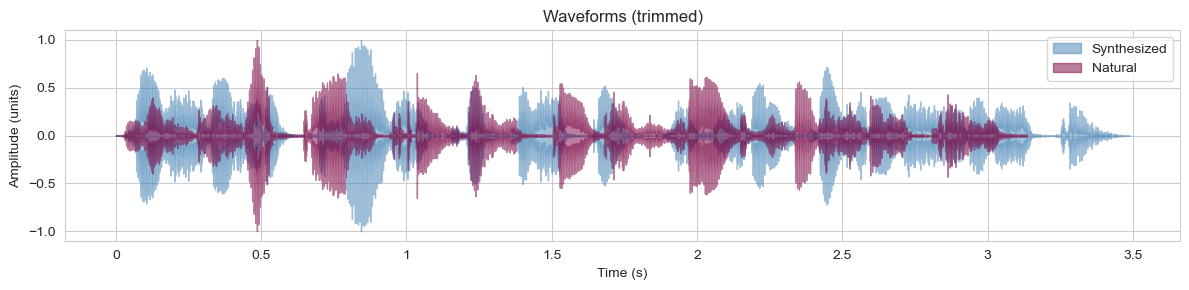

In [186]:
# detect speech onset/offset in each signal (start and end sample indices)
_, (s_nat, e_nat) = librosa.effects.trim(y_nat, top_db=30) 
_, (s_syn, e_syn) = librosa.effects.trim(y_syn, top_db=30)
print(f"Natural:     speech {s_nat/sr:.2f} - {e_nat/sr:.2f} s  ({(e_nat-s_nat)/sr:.2f} s)")
print(f"Synthesized: speech {s_syn/sr:.2f} - {e_syn/sr:.2f} s  ({(e_syn-s_syn)/sr:.2f} s)")

# align: cut the leading silence so both start at t = 0
y_nat_a = y_nat[s_nat:e_nat]
y_syn_a = y_syn[s_syn:e_syn]

# normalize amplitude (the loudest point recorded in the audio waveform it is known as the peak normalization)
y_nat_a = y_nat_a / np.max(np.abs(y_nat_a))
y_syn_a = y_syn_a / np.max(np.abs(y_syn_a))

fig, ax = plt.subplots(figsize=(12, 3))
librosa.display.waveshow(y_syn_a, sr=sr, color="steelblue", alpha=0.5, ax=ax, label="Synthesized")
librosa.display.waveshow(y_nat_a, sr=sr, color="#78003F", alpha=0.5, ax=ax, label="Natural")
ax.set(title="Waveforms (trimmed)",
       xlabel="Time (s)", ylabel="Amplitude (units)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

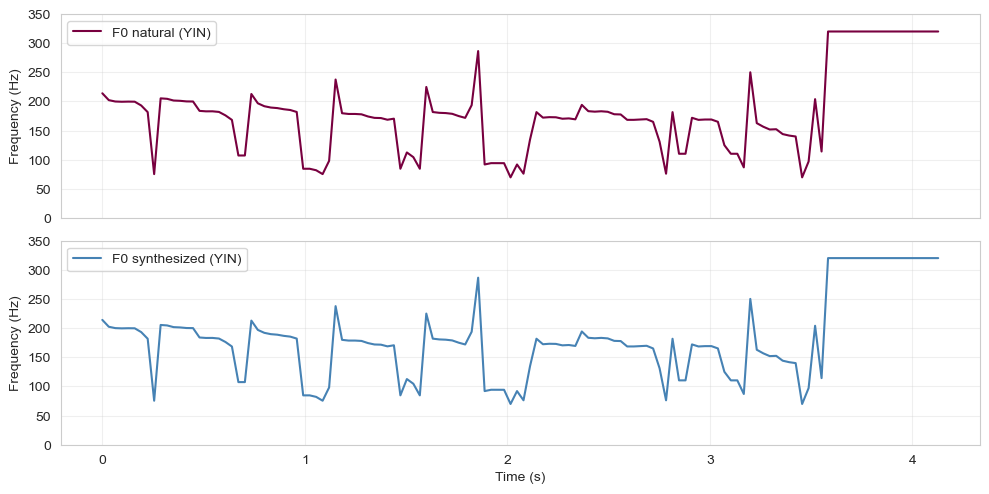

In [187]:
# Extract F0 with YIN (same range for both signals)
f0_nat = librosa.yin(y, fmin=70, fmax=320, sr=sr)
f0_syn = librosa.yin(y_syn, fmin=70, fmax=320, sr=sr_syn)

times_nat = librosa.times_like(f0_nat, sr=sr)
times_syn = librosa.times_like(f0_syn, sr=sr_syn)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, sharey=True)

axes[0].plot(times_nat, f0_nat, color="#78003F", label="F0 natural (YIN)")
#axes[0].set_title("Fundamental frequency contour of natural signal")

axes[1].plot(times_syn, f0_syn, color="steelblue", label="F0 synthesized (YIN)")
#axes[1].set_title("Fundamental frequency contour of synthesized signal")

for ax in axes:
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(0, 350)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left")
axes[1].set_xlabel("Time (s)")

plt.tight_layout()
fig.savefig("images/f0_en.pdf", dpi=300, bbox_inches="tight")
plt.show()

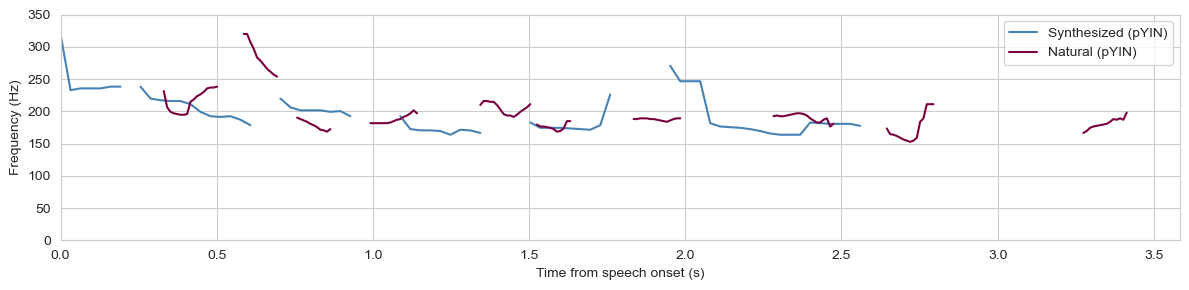

In [229]:
f0_nat, voiced_nat, _ = librosa.pyin(y, fmin=70, fmax=320, sr=sr)
f0_syn, voiced_syn, _ = librosa.pyin(y_syn, fmin=70, fmax=320, sr=sr_syn)

# align at speech onset (onset_nat, onset_syn from your waveform cell)
times_nat = librosa.times_like(f0_nat, sr=sr) - onset_nat
times_syn = librosa.times_like(f0_syn, sr=sr_syn) - onset_syn

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(times_syn, f0_syn, color="steelblue", lw=1.5, label="Synthesized (pYIN)")
ax.plot(times_nat, f0_nat, color="#78003F", lw=1.5, label="Natural (pYIN)")

ax.set_xlabel("Time from speech onset (s)")
ax.set_ylabel("Frequency (Hz)")
ax.set_xlim(0, None)
ax.set_ylim(0, 350)
ax.grid(True)
ax.legend()

plt.tight_layout()
fig.savefig("images/f0_en_pyin.pdf", dpi=300, bbox_inches="tight")
plt.show()

**In the report:**

✓ Provide information about the reference recording (duration, sampling frequency, and audio format);

**[Answer].** The reference recording (reference_en.wav) is a WAV file (Mono, a single audio track) with a duration of 3.981 seconds and a sampling frequency of 48 kHz.

✓ Write your opinion about the quality of the synthesized speech.

**[Answer].** The synthesized speech is correctly pronounced, every word can be understood, and the voice sounds fairly natural for a pretrained zero-shot model. The main difference: the synthesized speech is slower.

✓ Plot the waveforms, magnitude spectra, and fundamental frequency (F0) contours of the natural and synthesized signals;

**[The images shown above]**.

✓ Compare the obtained plots and comment on the observed differences in signal duration, spectral characteristics, and fundamental frequency patterns.

**[Answer].** \
**Waveforms**: The output is 0.2 s longer, and the amplitude of the synthesized signal is also more uniform, whereas the natural speech shows greater dynamic variation. Both signals have clean, near zero silence at the start and end, so the recordings have little background noise \
**Magnitude spectra**: \
**F0 contours**: The fundamental frequency ranges approximately from 70 Hz to 320 Hz. The synthesized speech has a smoother pitch contour, more step-like changes; the natural speech varies more. 

# 2. Zero-Shot Speech Synthesis (Lithuanian)

Record yourself saying the following Lithuanian sentence: “Tai yra šnekos sintezės sistemos
testas.” Save the recording as “reference_lt.wav.”

#### Load the file

In [47]:
filename = 'reference_lt.wav'
y_lt, sr_lt = librosa.load(filename, sr=None, mono=True) # load the audio file with its original sampling rate
# sr=None uses the native sampling rate
# mono=True convert signal to mono

#### Listen to playback

In [48]:
Audio(data=y_lt, rate=sr_lt) # listen to playback

### Information about the reference recording (duration, sampling frequency, and audio format);

In [189]:
import soundfile as sf
import os

path = "reference_lt.wav"
info = sf.info(path)

print("File size:       ", os.path.getsize(path), "bytes") # 363 KB on disk - storage size
print("Duration:        ", round(info.duration, 3), "seconds")
print("Sampling rate:   ", info.samplerate, "Hz") # 48 kHz - standard for phones, laptops and video.
print("Channels:        ", info.channels)     # 1 - Mono, a single audio track
print("Format:          ", info.format)       # WAV (Microsoft) [WAV]
print("Subtype (bit depth):", info.subtype)   # Signed 16 bit PCM [PCM_16]

File size:        363428 bytes
Duration:         3.785 seconds
Sampling rate:    48000 Hz
Channels:         1
Format:           WAV
Subtype (bit depth): PCM_16


### Speech synthesis

Using the pretrained YourTTS model, synthesize the same sentence. Since Lithuanian is not
supported by the pretrained model, use the English language setting.

In [190]:
tts.tts_to_file(
text="Tai yra šnekos sintezės sistemos testas.",
speaker_wav="reference_lt.wav",
language="en",
file_path="output_lt.wav"
)

 > Text splitted to sentences.
['Tai yra šnekos sintezės sistemos testas.']
 > Processing time: 10.8444344997406
 > Real-time factor: 2.5667300591102014


'output_lt.wav'

#### Load the file

In [191]:
y_lt_syn, sr_lt_syn = librosa.load("output_lt.wav", sr=None)

#### Listen to playback

In [151]:
Audio(data=y_lt_syn, rate=sr_lt_syn) # listen to playback

### Information about the synthesized recording (duration, sampling frequency, and audio format);

In [192]:
import soundfile as sf
import os

path = "output_lt.wav"
info = sf.info(path)

print("File size:       ", os.path.getsize(path), "bytes") # 130 KB on disk - storage size
print("Duration:        ", round(info.duration, 3), "seconds")
print("Sampling rate:   ", info.samplerate, "Hz") # 16 kHz
print("Channels:        ", info.channels)     # 1 - Mono, a single audio track
print("Format:          ", info.format)       # WAV (Microsoft) [WAV]
print("Subtype (bit depth):", info.subtype)   # Signed 16 bit PCM [PCM_16]

File size:        135244 bytes
Duration:         4.225 seconds
Sampling rate:    16000 Hz
Channels:         1
Format:           WAV
Subtype (bit depth): PCM_16


### Comparison

onset natural 0.35 s, synthesized 0.00 s, shift = 0.35 s


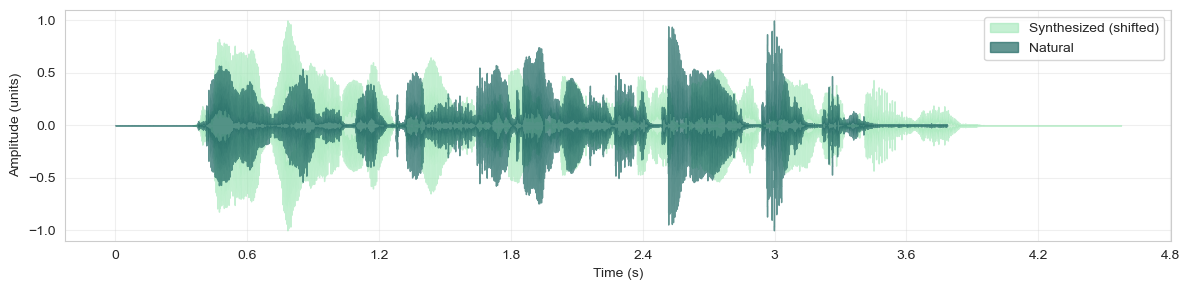

In [193]:
sr_norm = 16000
y_nat, _ = librosa.load("reference_lt.wav", sr=sr_norm, mono=True)
y_syn, _ = librosa.load("output_lt.wav", sr=sr_norm, mono=True)

# where speech starts in each signal (sample index)
_, (s_nat, e_nat) = librosa.effects.trim(y_nat, top_db=30)
_, (s_syn, e_syn) = librosa.effects.trim(y_syn, top_db=30)

# convert to seconds
onset_nat = s_nat / sr
onset_syn = s_syn / sr_syn
shift = onset_nat - onset_syn
print(f"onset natural {onset_nat:.2f} s, synthesized {onset_syn:.2f} s, shift = {shift:.2f} s")

# peak normalization
y_nat_n = y_nat / np.max(np.abs(y_nat))
y_syn_n = y_syn / np.max(np.abs(y_syn))

fig, ax = plt.subplots(figsize=(12, 3))

librosa.display.waveshow(y_syn_n, sr=sr_syn, color="#9fe7b6", alpha=0.6, ax=ax,
                         label="Synthesized (shifted)", offset=shift)
librosa.display.waveshow(y_nat_n, sr=sr, color="#236b66", alpha=0.7, ax=ax,
                         label="Natural")

ax.set(xlabel="Time (s)", ylabel="Amplitude (units)")
      #title="Multiple waveforms (normalized)")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig("images/waveforms_lt.pdf", dpi=300, bbox_inches="tight")
plt.show()

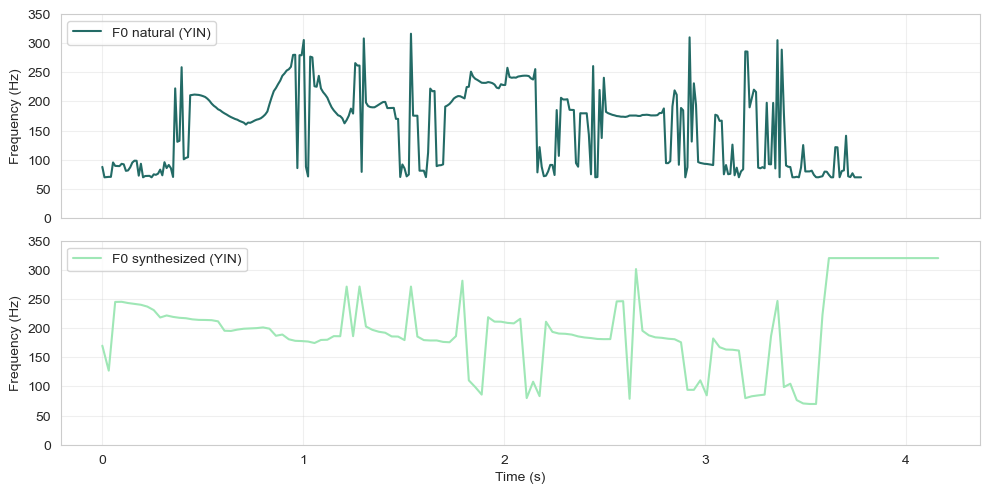

In [154]:
# Extract F0 with YIN (same range for both signals)
f0_nat = librosa.yin(y_lt, fmin=70, fmax=320, sr=sr_lt)
f0_syn = librosa.yin(y_lt_syn, fmin=70, fmax=320, sr=sr_lt_syn)

times_nat = librosa.times_like(f0_nat, sr=sr_lt)
times_syn = librosa.times_like(f0_syn, sr=sr_lt_syn)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, sharey=True)

axes[0].plot(times_nat, f0_nat, color="#236b66", label="F0 natural (YIN)")
#axes[0].set_title("Fundamental frequency contour of natural signal")

axes[1].plot(times_syn, f0_syn, color="#9fe7b6", alpha=1, label="F0 synthesized (YIN)")
#axes[1].set_title("Fundamental frequency contour of synthesized signal")

for ax in axes:
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(0, 350)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left")
axes[1].set_xlabel("Time (s)")

plt.tight_layout()
fig.savefig("images/f0_lt.pdf", dpi=300, bbox_inches="tight")
plt.show()

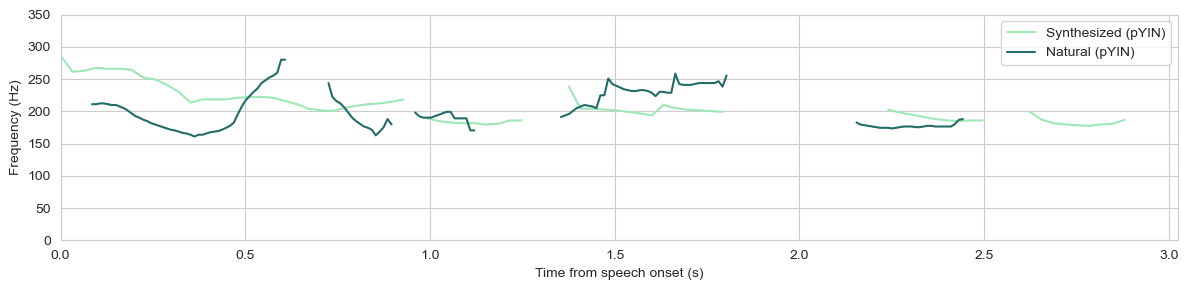

In [194]:
f0_nat, voiced_nat, _ = librosa.pyin(y_lt, fmin=70, fmax=320, sr=sr_lt)
f0_syn, voiced_syn, _ = librosa.pyin(y_lt_syn, fmin=70, fmax=320, sr=sr_lt_syn)

# align at speech onset (onset_nat, onset_syn from your waveform cell)
times_nat = librosa.times_like(f0_nat, sr=sr_lt) - onset_nat
times_syn = librosa.times_like(f0_syn, sr=sr_lt_syn) - onset_syn

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(times_syn, f0_syn, color="#9fe7b6", lw=1.5, label="Synthesized (pYIN)")
ax.plot(times_nat, f0_nat, color="#236b66", lw=1.5, label="Natural (pYIN)")

ax.set_xlabel("Time from speech onset (s)")
ax.set_ylabel("Frequency (Hz)")
ax.set_xlim(0, None)
ax.set_ylim(0, 350)
ax.grid(True)
ax.legend()

plt.tight_layout()
fig.savefig("images/f0_lt_pyin.pdf", dpi=300, bbox_inches="tight")
plt.show()

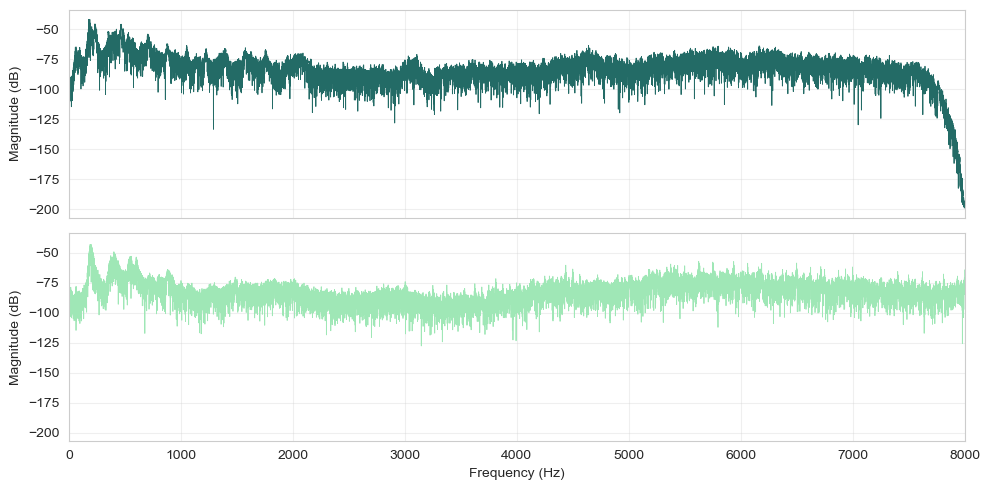

In [195]:
import os
import numpy as np
import librosa
import matplotlib.pyplot as plt

y_lt, sr_lt = librosa.load("reference_lt.wav", sr=None, mono=True)
y_lt_syn, sr_lt_syn = librosa.load("output_lt.wav", sr=None, mono=True)

# resample natural to the synthesized rate (originals stay untouched)
y_lt16 = librosa.resample(y_lt, orig_sr=sr_lt, target_sr=sr_lt_syn)

# peak normalization
y_lt16_n = y_lt16 / np.max(np.abs(y_lt16))
y_lt_syn_n = y_lt_syn / np.max(np.abs(y_lt_syn))

def magnitude_spectrum_db(y, sr):
    N = len(y)
    X = np.fft.rfft(y * np.hanning(N))
    mag_db = 20 * np.log10(np.abs(X) / N + 1e-10)
    freqs = np.fft.rfftfreq(N, d=1 / sr)
    return freqs, mag_db

freqs_nat, db_nat = magnitude_spectrum_db(y_lt16_n, sr_lt_syn)
freqs_syn, db_syn = magnitude_spectrum_db(y_lt_syn_n, sr_lt_syn)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, sharey=True)

axes[0].plot(freqs_nat, db_nat, color="#236b66", linewidth=0.6)
axes[1].plot(freqs_syn, db_syn, color="#9fe7b6", linewidth=0.6)
axes[1].set_xlabel("Frequency (Hz)")

for ax in axes:
    ax.set_ylabel("Magnitude (dB)")
    ax.set_xlim(0, 8000)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
os.makedirs("images", exist_ok=True)
fig.savefig("images/magnitude_lt.pdf", dpi=300, bbox_inches="tight")
plt.show()

**In the report:**

✓ Write your opinion about the quality of the synthesized speech.

**[Answer]**.

✓ Plot the waveforms, magnitude spectra, and fundamental frequency (F0) contours of the natural and synthesized signals;

**[The images shown above]**.

✓ Compare the obtained plots and comment on the observed differences in signal duration, spectral characteristics, and fundamental frequency patterns.

**[Answer]**. \
**Waveforms**: \
**Magnitude spectra**: \
**F0 contours**: The natural speech F0 contour shows irregular pitch variations. The synthesized speech F0 contour is smoother and has more stable parts.

# 3. Lithuanian Dataset Preparation

Use the **Lithuanian Emotional Speech Corpus (EMO)**.

Emotion labels used in the EMO corpus: `D – Joy (Džiaugsmas), L – Sadness (Liūdesys), N
– Surprise (Nuostaba), P – Anger (Pyktis), Z – Neutral (Neutrali)`.

Download only **one WAV archive (e.g., emo-wavs.zip.012)**

Select:
- one emotion only;
- one speaker;
- corresponding speech recordings and transcriptions.

**Steps:**
1. Install a free archive tool. On Windows use 7-Zip (7-zip.org).
2. Open the `emo-wavs.zip.012` file with 7-Zip tool. Right-click it, then "Open with", choose 7-Zip File Manager.
4. Open `\wavs` folder.
5. Select emotion’s folder (`\P` – Anger (Pyktis)).
6. Select folder correspoding to groups of speakers (`\F3` – female, 18-60 years)
7. Select one speaker `1201-F3P`
8. Choose "Extract files" into a new folder.
9. Download archive `emo-grid.zip`.
10. Open the `emo-grid.zip` file with 7-Zip tool. Right-click it, then "Open with", choose 7-Zip File Manager.
11. Open `\grid` folder.
12. Repeat 5-8 steps.

Split the selected recordings into training (90%) and validation (10%) sets.

Prepare the dataset in the required TTS format. 

The metadata should contain the correspondence between each speech recording and its
transcription (read more: https://coqui-tts.readthedocs.io/en/latest/datasets/formatting_your_dataset.html)

In [57]:
import os

print("Current folder:", os.getcwd())

for file in os.listdir("."):
    print(file)

Current folder: C:\Users\eveli\OneDrive\Documents\NLP\Lab3
.ipynb_checkpoints
dataset
dataset2
emo-wavs.zip.012
grid
images
Lab_3_EV.ipynb
metadata_of_EMO_dataset.csv
output.wav
output_lt.wav
README.pdf
reference_en.wav
reference_lt.wav
Task 3_2026.pdf
Task 3_2026_Additional_Task.pdf
wavs


In [58]:
import os
import zipfile

archive = os.path.abspath("emo-wavs.zip.012")

print("File exists:", os.path.exists(archive))
print("Full path:", archive)

if os.path.exists(archive):
    print("Is a normal ZIP file:", zipfile.is_zipfile(archive))
    print("File size:", os.path.getsize(archive), "bytes")

File exists: True
Full path: C:\Users\eveli\OneDrive\Documents\NLP\Lab3\emo-wavs.zip.012
Is a normal ZIP file: False
File size: 10737418240 bytes


### Example of audio and transcription

In [59]:
y, sr = librosa.load("wavs/1201-F3P-0278.wav", sr=None)
Audio(data=y, rate=sr) 

In [60]:
textgrid_path = "grid/1201-F3P-0278.TextGrid"

with open(textgrid_path, "r", encoding="utf-8-sig") as file:
    print(file.read()[:5000])

File type = "ooTextFile"
Object class = "TextGrid"

xmin = 0 
xmax = 5.6099999999999 
tiers? <exists> 
size = 5 
item []: 
    item [1]:
        class = "IntervalTier" 
        name = "phones" 
        xmin = 0 
        xmax = 5.6099999999999 
        intervals: size = 72 
        intervals [1]:
            xmin = 0 
            xmax = 0.10400000000004184 
            text = "t" 
        intervals [2]:
            xmin = 0.10400000000004184 
            xmax = 0.16399999999998727 
            text = "U" 
        intervals [3]:
            xmin = 0.16399999999998727 
            xmax = 0.19399999999995998 
            text = "n'" 
        intervals [4]:
            xmin = 0.19399999999995998 
            xmax = 0.35400000000004184 
            text = "ie" 
        intervals [5]:
            xmin = 0.35400000000004184 
            xmax = 0.42399999999997817 
            text = "k" 
        intervals [6]:
            xmin = 0.42399999999997817 
            xmax = 0.4840000000000373 
     

### File format for annotations

In [61]:
import re

path = "grid/1201-F3P-0278.TextGrid"

with open(path, "r", encoding="utf-8-sig") as f:
    content = f.read()

# Separate the annotation tiers
tiers = re.split(r'\s*item \[\d+\]:', content)[1:]

for tier in tiers:
    name_match = re.search(r'name\s*=\s*"([^"]*)"', tier)

    if name_match:
        tier_name = name_match.group(1)

        # Get the text labels in this tier
        labels = re.findall(r'text\s*=\s*"([^"]*)"', tier)

        # Ignore empty labels
        labels = [x for x in labels if x.strip()]

        print(f"\nTier: {tier_name}")
        print("Text:", " ".join(labels[:100]))


Tier: phones
Text: t U n' ie k a d A n' e a t' s' i p r a S A J n' e s a t' s' i p r aA S' ii m a s' n' iE k oo n' e p a k' E J s k a j t U v' I s' t' Ie k k a r t Oo j' i k l a j d A s

Tier: syll
Text: t U n' ie k a d A n' e a t' s' i p r a S A J n' e s a t' s' i p r aA S' ii m a s' n' iE k oo n' e p a k' E J s k a j t U v' I s' t' Ie k k a r t Oo j' i k l a j d A s

Tier: words
Text: tu niekada neatsiprašai nes atsiprašymas nieko nepakeis kai tu vis tiek kartoji klaidas

Tier: phono
Text: t U+n' ie-k a-d A+n' e-a t'-s' i-p r a-S A J+n' e s+a t'-s' i-p r aA-S' ii-m a s'+n' iE-k oo+n' e-p a-k' E J s+k a j+t U+v' I s'+t' Ie k+k a r-t Oo-j' i+k l a j-d A s

Tier: ortho
Text: tu niekada neatsiprašai nes atsiprašymas nieko nepakeis kai tu vis tiek kartoji klaidas


### *Version 1.* Using transcription files

In [63]:
from pathlib import Path
import random, shutil
import tgt
import csv

SPEAKER = "12"
EMOTION = "P"
output_dir = Path("dataset2")

# WAV and TextGrid files
WAVS_DIR = Path("wavs")
GRID_DIR = Path("grid")

audio_by_id = {p.stem: p for p in WAVS_DIR.rglob("*.wav")}
grid_by_id  = {p.stem: p for p in GRID_DIR.rglob("*.TextGrid")}
print(len(audio_by_id), "wav files,", len(grid_by_id), "TextGrid files")

# [(file_id, text) extracting from the TextGrid files
rows = []
for file_id in sorted(audio_by_id):
    if file_id not in grid_by_id:
        continue
    code, tag, _ = file_id.split("-")            # 1201, F3P, 0147
    if code[:2] != SPEAKER or tag[-1] != EMOTION:
        continue

    tg = tgt.io.read_textgrid(str(grid_by_id[file_id]), encoding="utf-8")
    tier = tg.get_tier_by_name("ortho")          # tier with the written text
    text = " ".join(i.text.strip() for i in tier.intervals if i.text.strip())

    if text:
        rows.append((file_id, text))

print(len(rows), "recordings selected")

# Split selected recordings to training and validation
random.seed(42)
random.shuffle(rows)

split_index = int(len(rows) * 0.9)
train_rows = rows[:split_index]
val_rows = rows[split_index:]

# Copy audio files
wavs_dir = output_dir / "wavs"
wavs_dir.mkdir(parents=True, exist_ok=True)

for file_id, text in rows:
    destination = wavs_dir / f"{file_id}.wav"
    if not destination.exists():
        shutil.copy2(audio_by_id[file_id], destination)

# metadata files
def write_metadata(filename, data):
    with open(output_dir / filename, "w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f, delimiter="|", lineterminator="\n")
        for file_id, text in data:
            writer.writerow([file_id, text, text])

write_metadata("metadata_train.csv", train_rows)
write_metadata("metadata_val.csv", val_rows)

print("Training recordings:", len(train_rows))
print("Validation recordings:", len(val_rows))
print("Dataset saved to:", output_dir.resolve())

298 wav files, 298 TextGrid files
298 recordings selected
Training recordings: 268
Validation recordings: 30
Dataset saved to: C:\Users\eveli\OneDrive\Documents\NLP\Lab3\dataset2


### *Version 2*. Using metadata

In [64]:
from pathlib import Path
import random, shutil

SPEAKER = "12"      # 1201-F3P
EMOTION = "P"       # Anger
META = Path("metadata_of_EMO_dataset.csv")
OUT = Path("dataset")

# Find all wav files
wav_files = {}
for p in Path(".").rglob("*.wav"): # searches the current folder and all subfolders
    if "dataset" not in p.parts:   # skip the output folder
        wav_files[p.stem] = p

# Find speaker and emotion in metadata
rows = []
for line in open(META, encoding="utf-8-sig"):
    parts = line.strip().split("|")
    if len(parts) < 3:
        continue
    path, speaker, text = parts[0], parts[1], parts[2]

    name = Path(path).stem               # 1201-F3P-0001 -> ["1201", "F3P", "0001"]
    emotion = name.split("-")[1][-1]     # last letter of the middle part

    if speaker == SPEAKER and emotion == EMOTION and name in wav_files and text:
        rows.append((wav_files[name], text))

print(len(rows), "recordings")

# Split selected recordings to training and validation
random.seed(42)
random.shuffle(rows)

split = int(len(rows) * 0.9)
train_rows = rows[:split]
val_rows = rows[split:]

# Save wavs and metadata files
(OUT / "wavs").mkdir(parents=True, exist_ok=True)

for filename, data in [("metadata_train.csv", train_rows), ("metadata_val.csv", val_rows)]:
    with open(OUT / filename, "w", encoding="utf-8") as f:
        for wav, text in data:
            new_name = wav.stem.split("-")[-1]      # 1201-F3P-0147 -> 0147
            shutil.copy(wav, OUT / "wavs" / f"{new_name}.wav")
            f.write(f"{new_name}|{text}|{text}\n")
            
print("Training recordings:", len(train_rows))
print("Validation recordings:", len(val_rows))
print("Dataset saved to:", OUT.resolve())

298 recordings
Training recordings: 268
Validation recordings: 30
Dataset saved to: C:\Users\eveli\OneDrive\Documents\NLP\Lab3\dataset


### Confirmation that there is no recordings overlap between the training and test sets

In [65]:
train_ids = [l.split("|")[0] for l in open(OUT / "metadata_train.csv", encoding="utf-8")]
val_ids   = [l.split("|")[0] for l in open(OUT / "metadata_val.csv", encoding="utf-8")]

overlap = set(train_ids) & set(val_ids)
print("Recordings in both files:", len(overlap))    # should be 0

Recordings in both files: 0


### The structure 

In [ ]:
from pathlib import Path

space  = '    '
branch = '│   '
tee    = '├── '
last   = '└── '

def tree(dir_path: Path, prefix: str = '', max_files: int = 3):
    contents = sorted(dir_path.iterdir())
    dirs  = [p for p in contents if p.is_dir()]
    files = [p for p in contents if p.is_file()]

    shown = dirs + files[:max_files]
    hidden = len(files) - max_files          # files not shown

    pointers = [tee] * (len(shown) - 1) + [last]
    if hidden > 0:
        pointers = [tee] * len(shown) + [last]   # last line is the "..." line

    for pointer, path in zip(pointers, shown):
        yield prefix + pointer + path.name + ('/' if path.is_dir() else '')
        if path.is_dir():
            extension = branch if pointer == tee else space
            yield from tree(path, prefix + extension, max_files)

    if hidden > 0:
        yield prefix + last + f"... ({len(files)} files in total)"

print(OUT.name + "/")

for line in tree(OUT):
    print(line)

In [66]:
wav_list = sorted((OUT / "wavs").glob("*.wav"))

print("\nNumber of wav files:", len(wav_list))
print("Training:  ", len(open(OUT / "metadata_train.csv", encoding="utf-8").readlines()))
print("Validation:", len(open(OUT / "metadata_val.csv", encoding="utf-8").readlines()))

print("\nFirst lines of metadata_train.csv:")
print(*open(OUT / "metadata_train.csv", encoding="utf-8").readlines()[:3], sep="")

print("First lines of metadata_val.csv:")
print(*open(OUT / "metadata_val.csv", encoding="utf-8").readlines()[:3], sep="")


Number of wav files: 298
Training:   268
Validation: 30

First lines of metadata_train.csv:
0243|tu net neatsiprašei nes nemanau kad padariau ką nors blogo|tu net neatsiprašei nes nemanau kad padariau ką nors blogo
0295|nes kai padedu tu vis tiek kaltini|nes kai padedu tu vis tiek kaltini
0169|ar neturit kuo užsiimti išsideginkit akis velniai jūs palaukit ateis tėvai nesibaigs jum geruoju|ar neturit kuo užsiimti išsideginkit akis velniai jūs palaukit ateis tėvai nesibaigs jum geruoju

First lines of metadata_val.csv:
0111|nemėgstu kai mano nuomone|nemėgstu kai mano nuomone
0080|o kodėl ne tas tipas kur dešras kemša|o kodėl ne tas tipas kur dešras kemša
0276|ne visada tik tada kai tu klysti|ne visada tik tada kai tu klysti



## Information about recordings

### Total number, total duration of selected recordings

In [67]:
import soundfile as sf

OUT = Path("dataset")

def total_duration(files):
    return sum(sf.info(f).duration for f in files)

wav_list = sorted((OUT / "wavs").glob("*.wav"))
seconds = total_duration(wav_list)

print("Total number of recordings:", len(wav_list))
print("Total duration:", round(seconds, 1), "seconds")
print("               =", round(seconds / 60, 1), "minutes")

Total number of recordings: 298
Total duration: 718.9 seconds
               = 12.0 minutes


### Main audio parameters (sampling frequency, bit depth, number of channels)

In [68]:
import soundfile as sf
from collections import Counter

OUT = Path("dataset")          # or Path("dataset")
wav_list = sorted((OUT / "wavs").glob("*.wav"))

info = sf.info(wav_list[0])
print("Example file:", wav_list[0].name)
print("Sampling frequency:", info.samplerate, "Hz")
print("Channels:", info.channels)
print("Format / subtype:", info.format, "/", info.subtype)
print("Bit depth:", info.subtype.split("_")[1], "bit")   # e.g. 24 bit

# All files
params = Counter((sf.info(f).samplerate, sf.info(f).channels, sf.info(f).format, sf.info(f).subtype.split("_")[1])
                 for f in wav_list)
print("\nAll files (sampling rate, channels, subtype): number of files")
for p, n in params.items():
    print(p, ":", n)

Example file: 0001.wav
Sampling frequency: 96000 Hz
Channels: 1
Format / subtype: WAVEX / PCM_24
Bit depth: 24 bit

All files (sampling rate, channels, subtype): number of files
(96000, 1, 'WAVEX', '24') : 298


### Duration of the selected recordings

In [69]:
import soundfile as sf
import matplotlib.pyplot as plt

OUT = Path("dataset")
wav_list = sorted((OUT / "wavs").glob("*.wav"))

durations = [sf.info(f).duration for f in wav_list]

print("Number of recordings:", len(durations))
print("Minimum duration:", round(min(durations), 2), "seconds")
print("Maximum duration:", round(max(durations), 2), "seconds")
print("Average duration:", round(sum(durations) / len(durations), 2), "seconds")

Number of recordings: 298
Minimum duration: 0.84 seconds
Maximum duration: 7.77 seconds
Average duration: 2.41 seconds


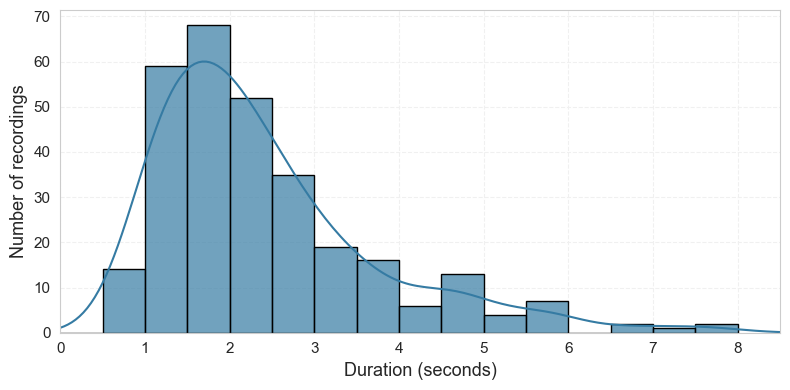

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

color = sns.color_palette("mako", 5)[2]

bins = np.arange(0, np.max(durations) + 0.5, 0.5)  
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(durations, bins=bins, kde=True, kde_kws={"cut": 3, "clip": (0, None)},   # extend the curve, but not below 0
             color=color, edgecolor="black", alpha=0.7, ax=ax)

ax.set_xlabel("Duration (seconds)", fontsize=13)
ax.set_ylabel("Number of recordings", fontsize=13)
ax.grid(True, color="#f0f0f0", axis='both', linestyle="--")
ax.set_axisbelow(True)
ax.tick_params(labelsize=11)
ax.set_xlim(0, np.ceil(np.max(durations)) + 0.5)

fig.tight_layout()
fig.savefig("images/durations_recordings.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Information about recordings in the training and validation sets.

In [71]:
import soundfile as sf
import pandas as pd
from statistics import median

OUT = Path("dataset")

def get_durations(metadata_file):
    with open(OUT / metadata_file, encoding="utf-8") as f:
        ids = [line.split("|")[0] for line in f]
    return [sf.info(OUT / "wavs" / f"{i}.wav").duration for i in ids]

train_dur = get_durations("metadata_train.csv")
val_dur = get_durations("metadata_val.csv")
all_dur = train_dur + val_dur

def summary(name, d):
    return {
        "Set": name,
        "Recordings": len(d),
        "Share (%)": round(len(d) / len(all_dur) * 100, 1),
        "Total (min)": round(sum(d) / 60, 1),
        "Min (s)": round(min(d), 2),
        "Max (s)": round(max(d), 2),
        "Average (s)": round(sum(d) / len(d), 2),
        "Median (s)": round(median(d), 2)
    }

table = pd.DataFrame([
    summary("Training", train_dur),
    summary("Validation", val_dur),
    summary("Total", all_dur),
])
table

,Set,Recordings,Share (%),Total (min),Min (s),Max (s),Average (s),Median (s)
0,Training,268,89.9,10.8,0.84,7.77,2.43,2.05
1,Validation,30,10.1,1.1,0.96,4.92,2.28,2.05
2,Total,298,100.0,12.0,0.84,7.77,2.41,2.05


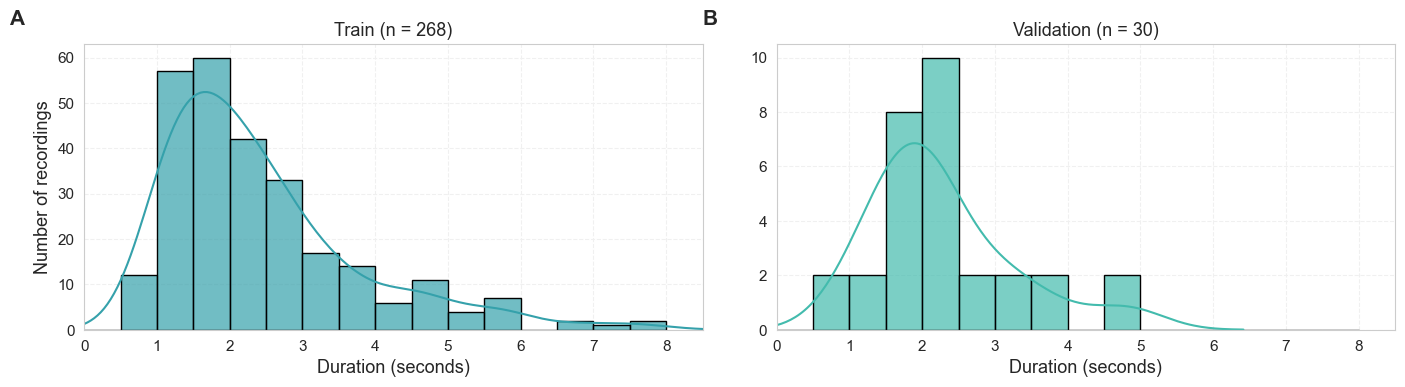

In [72]:
import string
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

datasets = [train_dur, val_dur]
titles = ["Train", "Validation"]
colors = ["#35A1ABFF", "#43BBADFF"]   # two shades of mako

# shared bins and x range for both plots
max_dur = max(np.max(train_dur), np.max(val_dur))
bins = np.arange(0, max_dur + 0.5, 0.5)
x_max = np.ceil(max_dur) + 0.5

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)

for i, (ax, data, title) in enumerate(zip(axes, datasets, titles)):
    sns.histplot(data, bins=bins, kde=True,
                 kde_kws={"cut": 3, "clip": (0, None)},
                 color=colors[i], edgecolor="black", alpha=0.7, ax=ax)

    ax.set_title(f"{title} (n = {len(data)})", fontsize=13)
    ax.set_xlabel("Duration (seconds)", fontsize=13)
    ax.set_ylabel("Number of recordings" if i == 0 else "", fontsize=13)

    ax.grid(True, color="#f0f0f0", axis='both', linestyle="--")
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=11)

    ax.set_xlim(0, x_max)
    ax.set_xticks(np.arange(0, x_max, 1))

    # panel letter (A, B)
    ax.text(-0.12, 1.12, string.ascii_uppercase[i], transform=ax.transAxes,
            fontsize=15, fontweight='bold', va='top')

fig.tight_layout()
fig.savefig("images/durations_train_val.pdf", dpi=300, bbox_inches="tight")
plt.show()

**In the report:**

✓ specify the selected speaker and emotion;

**[Answer].** \
Speaker: 12 (session 01, female, 18-60 years);\
Emotion: P - Anger (Pyktis)

✓ report the total number and total duration of selected recordings;

**[Answer].** \
Total number of recordings: 298 \
Total duration: 718.9 seconds = 12 minutes

✓ provide the main audio parameters (sampling frequency, bit depth, number of channels);

**[Answer].** \
Sampling frequency: 96000 Hz = 96 kHz \
Channels: 1 \
Format: WAVEX \
Bit depth: 24 bit

✓ report the minimum, maximum, and average duration of the selected recordings and plot a histogram of recording durations;

**[Answer].** \
Minimum duration: 0.84 seconds \
Maximum duration: 7.77 seconds \
Average duration: 2.41 seconds \
The histogram shown above.

✓ report the number of recordings in the training and validation sets.

**[Answer].** \
Table shown above.